<a href="https://colab.research.google.com/github/GopalKrishna-India/Geospatial/blob/master/SpectralLib-Trees/Mango_SpectralLib_Sentinel2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Earth Engine initialized successfully.
Extracting spectra for 472 samples in batches of 50...
  Processed 50 / 472
  Processed 100 / 472
  Processed 150 / 472
  Processed 200 / 472
  Processed 250 / 472
  Processed 300 / 472
  Processed 350 / 472
  Processed 400 / 472
  Processed 450 / 472
  Processed 472 / 472
Spectra extraction complete.


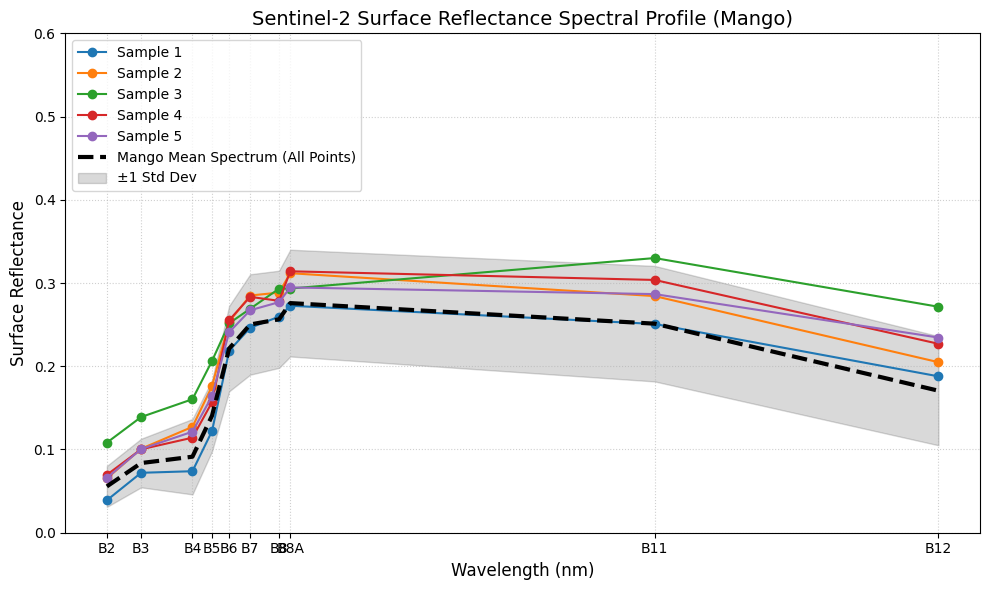

In [2]:
# ==============================================================================
# 1. INITIALIZATION & SETUP
# ==============================================================================
import ee
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------
# 1. Initialize Earth Engine API
# -------------------------------------------------------------------
try:
    ee.Initialize(project='ee-geoinformers')
    print("Earth Engine initialized successfully.")
except Exception as e:
    print("Initializing EE with authentication prompt...")
    ee.Authenticate()
    ee.Initialize(project='ee-geoinformers')
# ==============================================================================
# 2. USER CONFIGURATION
# ==============================================================================
SAMPLE_ASSET = 'projects/eeciforicraf/assets/SpectralLib/Mango/Mango_LatLong_CSV'
SAMPLE_ID_FIELD = 'SN'
SPECIES_FIELD = 'TreeSpecies'
FIELD_DATE_FIELD = 'Date'
MATCH_WINDOW_DAYS = 45

# Native S2 Bands & Derived Indices
BANDS_10M = ['B2', 'B3', 'B4', 'B8']
BANDS_20M = ['B5', 'B6', 'B7', 'B8A', 'B11', 'B12']
CORE_BANDS = BANDS_10M + BANDS_20M
ALL_PROFILE_BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']

# Band center wavelengths in nanometers for accurate spectral plotting
WAVELENGTHS = [490, 560, 665, 705, 740, 783, 842, 865, 1610, 2190]

# ==============================================================================
# 3. GEOMETRY RECONSTRUCTION & PREPROCESSING
# ==============================================================================
raw_samples = ee.FeatureCollection(SAMPLE_ASSET)

def reconstruct_geometry(feature):
    props = feature.propertyNames()

    # Check possible coordinate column names
    lat_keys = ee.List(['Latitude', 'latitude', 'lat', 'Lat', 'LAT'])
    lon_keys = ee.List(['Longitude', 'longitude', 'lon', 'Long', 'lng', 'LON'])

    lat_match = lat_keys.map(lambda k: ee.Algorithms.If(props.contains(k), k, None)).removeAll([None])
    lon_match = lon_keys.map(lambda k: ee.Algorithms.If(props.contains(k), k, None)).removeAll([None])

    lat_val = ee.Algorithms.If(lat_match.size().gt(0), feature.get(lat_match.get(0)), None)
    lon_val = ee.Algorithms.If(lon_match.size().gt(0), feature.get(lon_match.get(0)), None)

    is_valid = ee.Algorithms.If(lat_val, ee.Algorithms.If(lon_val, True, False), False)

    point_geom = ee.Algorithms.If(
        is_valid,
        ee.Geometry.Point([ee.Number.parse(ee.String(lon_val)), ee.Number.parse(ee.String(lat_val))]),
        None
    )
    return feature.setGeometry(ee.Geometry(point_geom)).set('is_valid_geom', is_valid)

samples = raw_samples.map(reconstruct_geometry)\
    .filter(ee.Filter.eq('is_valid_geom', True))\
    .filter(ee.Filter.notNull([SAMPLE_ID_FIELD, FIELD_DATE_FIELD]))

def mask_s2_sr(image):
    scl = image.select('SCL')
    clear_mask = scl.neq(0).And(scl.neq(1)).And(scl.neq(2)).And(scl.neq(3))\
        .And(scl.neq(7)).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))

    return image.select(CORE_BANDS).multiply(0.0001).updateMask(clear_mask)\
        .copyProperties(image, ['system:time_start', 'CLOUDY_PIXEL_PERCENTAGE'])

S2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')\
    .filterBounds(samples.geometry())\
    .map(mask_s2_sr)

# ==============================================================================
# 4. BATCHED EXTRACTION TO PREVENT MEMORY EXHAUSTION
# ==============================================================================
def extract_sample_spectrum(feature):
    geom = feature.geometry().buffer(20)
    date_str = ee.String(feature.get(FIELD_DATE_FIELD))
    field_date = ee.Date.parse('dd-MM-yyyy', date_str)

    start = field_date.advance(-MATCH_WINDOW_DAYS, 'day')
    end = field_date.advance(MATCH_WINDOW_DAYS + 1, 'day')

    best_scene = S2.filterDate(start, end)\
        .filterBounds(geom)\
        .sort('CLOUDY_PIXEL_PERCENTAGE')\
        .first()

    # Simple median reduction to keep memory low
    stats = ee.Algorithms.If(
        best_scene,
        ee.Image(best_scene).reduceRegion(
            reducer=ee.Reducer.median(),
            geometry=geom,
            scale=10,
            maxPixels=1e8,
            tileScale=8
        ),
        ee.Dictionary({})
    )

    return feature.toDictionary().combine(stats, True)

# Process client-side in batches of 50 features to prevent 400 HttpError
sample_list_ee = samples.toList(samples.size())
num_samples = samples.size().getInfo()
batch_size = 50

all_records = []

print(f"Extracting spectra for {num_samples} samples in batches of {batch_size}...")

for i in range(0, num_samples, batch_size):
    sub_list = sample_list_ee.slice(i, i + batch_size)
    sub_fc = ee.FeatureCollection(sub_list.map(lambda f: ee.Feature(None, extract_sample_spectrum(ee.Feature(f)))))

    # Retrieve current batch
    batch_data = sub_fc.getInfo()['features']
    all_records.extend([f['properties'] for f in batch_data])
    print(f"  Processed {min(i + batch_size, num_samples)} / {num_samples}")

df = pd.DataFrame(all_records)
print("Spectra extraction complete.")

# ==============================================================================
# 5. SPECTRAL PLOTTING
# ==============================================================================
plt.figure(figsize=(10, 6))

# Plot first 5 valid features
for i in range(min(5, len(df))):
    sample_row = df.iloc[i]
    spectrum = [sample_row.get(b, np.nan) for b in ALL_PROFILE_BANDS]
    plt.plot(WAVELENGTHS, spectrum, marker='o', linewidth=1.5, label=f"Sample {sample_row.get(SAMPLE_ID_FIELD, i)}")

# Plot mean and std deviation across all extracted records
df_bands = df[ALL_PROFILE_BANDS].apply(pd.to_numeric, errors='coerce')
mean_spectrum = df_bands.mean()
std_spectrum = df_bands.std()

plt.plot(WAVELENGTHS, mean_spectrum, color='black', linewidth=3, linestyle='--', label='Mango Mean Spectrum (All Points)')
plt.fill_between(WAVELENGTHS, mean_spectrum - std_spectrum, mean_spectrum + std_spectrum, color='black', alpha=0.15, label='±1 Std Dev')

plt.title('Sentinel-2 Surface Reflectance Spectral Profile (Mango)', fontsize=14)
plt.xlabel('Wavelength (nm)', fontsize=12)
plt.ylabel('Surface Reflectance', fontsize=12)
plt.xticks(WAVELENGTHS, labels=['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12'])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')
plt.ylim(0, 0.6)

plt.tight_layout()
plt.show()

# Save extracted spectral dataframe
df.to_csv('Mango_Sentinel2_Spectral_Library.csv', index=False)